# 07 — Diversidad genética, escalabilidad y validación con LinearSVC

Notebook orquestador del estudio adicional del TFM. Reutiliza el GA refactorizado
en `src/ga_core.py` (run_ga) y las métricas de `src/ga_metrics.py`.

**Contenido:** (1) diversidad genética por generación, (2) validación de S* con
LinearSVC sobre test held-out, (3) estabilidad de selección (R=10 semillas),
(4) speed-up por dataset, (5) tabla consolidada de escalabilidad algorítmica.

> Metodología held-out: el GA busca solo sobre *train*; S* se valida sobre *test*
> no visto. Los resultados difieren de los artefactos `ga_full_*` (búsqueda sobre
> el dataset completo), que se conservan intactos.

## 1. Setup

In [ ]:
import sys, os, time, csv, json, warnings
from datetime import datetime
sys.path.insert(0, '../src')

import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from spark_config import crear_sesion_spark, mostrar_info_spark, parar_spark
from datasets_loader import cargar_dataset
from ga_core import run_ga, evaluar_fitness
from ga_metrics import jaccard_mean, kuncheva_index, selection_frequency

warnings.filterwarnings('ignore', message='The least populated class in y')
# Gisette v1 figura como "inactive" en OpenML; el aviso es informativo (los datos
# son los del estudio) y se silencia para mantener limpia la salida del notebook.
warnings.filterwarnings('ignore', message='Version 1 of dataset gisette is inactive')
os.makedirs('../results', exist_ok=True)
print('Notebook 07 iniciado:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))

In [ ]:
spark = crear_sesion_spark(app_name='TFM_Diversidad_Escalabilidad',
                           master='local[*]', driver_memory='4g',
                           executor_memory='4g', ui_port=4040, verbose=False)
sc = spark.sparkContext
NUM_CORES = sc.defaultParallelism
mostrar_info_spark(spark, ui_port=4040)
print('Cores:', NUM_CORES)

# Los workers necesitan evaluar_fitness (de ga_core). En lugar de enviarlo con
# sc.addPyFile (que avisa "path ... has been added already" al re-ejecutar la
# celda), se registra el modulo para que cloudpickle lo serialice POR VALOR:
# la funcion viaja embebida en la tarea y el worker no importa el modulo.
from pyspark.cloudpickle import register_pickle_by_value
import ga_core, ga_metrics
register_pickle_by_value(ga_core)
register_pickle_by_value(ga_metrics)

In [13]:
DATASETS = {
    'wdbc':       dict(P=50,  G_max=50,  k_tourn=5, elite_size=2, p_init=0.5,
                       N_stop=10, cv_folds=5),
    'arrhythmia': dict(P=100, G_max=100, k_tourn=5, elite_size=5, p_init=0.5,
                       N_stop=15, cv_folds=3),
    'gisette':    dict(P=100, G_max=100, k_tourn=5, elite_size=5, p_init=0.1,
                       N_stop=15, cv_folds=5),
}
COMUNES = dict(p_cross=0.8, p_mut=0.2, eps_stop=0.001, alpha=0.9, beta=0.1)
SEED = 42

def construir_params(nombre, D):
    p = dict(COMUNES, **DATASETS[nombre])
    p['p_mut_bit'] = 1.0 / D
    return p

In [ ]:
def split_holdout(X, y, test_size=0.3, seed=SEED):
    """Split estratificado; cae a no-estratificado si hay clases con 1 muestra."""
    try:
        return train_test_split(X, y, test_size=test_size, stratify=y,
                                random_state=seed)
    except ValueError as e:
        print(f'  [aviso] estratificacion imposible ({e}); split sin estratificar')
        return train_test_split(X, y, test_size=test_size, random_state=seed)

def make_evaluador_spark(X_train, y_train, cv, alpha, beta, num_slices):
    """Devuelve un callable(pop)->list[fitness] que evalua con Spark RDD."""
    X_bc = sc.broadcast(X_train)
    y_bc = sc.broadcast(y_train)
    def _eval(pop):
        # Compactar a int8 antes de paralelizar: una lista de 5000 ints de Python
        # pesa ~10x mas que un array int8, lo que dispara el aviso de Spark
        # "task of very large size". Con int8 cada particion queda muy por debajo
        # de 1 MB (Gisette: 9 MB -> ~0.5 MB en total).
        pop_arr = list(np.asarray(pop, dtype=np.int8))
        rdd = sc.parallelize(pop_arr, numSlices=num_slices)
        return rdd.map(lambda c: evaluar_fitness(c, X_bc.value, y_bc.value,
                                                 cv, alpha, beta)).collect()
    _eval.broadcasts = (X_bc, y_bc)  # para destruir luego
    return _eval

## 2. Diversidad por generación + validación held-out (LinearSVC)

In [15]:
RESULTADOS = {}   # nombre -> dict con metricas para la tabla consolidada

for nombre in ['wdbc', 'arrhythmia', 'gisette']:
    print('=' * 60, f'\n{nombre.upper()}')
    X, y, feat, info = cargar_dataset(nombre)
    X = np.ascontiguousarray(X)
    D = X.shape[1]
    params = construir_params(nombre, D)

    X_tr, X_te, y_tr, y_te = split_holdout(X, y)
    print(f'  D={D}  train={X_tr.shape[0]}  test={X_te.shape[0]}')

    evaluador = make_evaluador_spark(X_tr, y_tr, params['cv_folds'],
                                     params['alpha'], params['beta'], NUM_CORES)
    t0 = time.time()
    res = run_ga(X_tr, y_tr, params, seed=SEED,
                 evaluador_poblacion=evaluador, collect_diversity=True, verbose=True)
    for bc in evaluador.broadcasts:
        bc.destroy()
    print(f'  GA: {res["generaciones_ejecutadas"]} gen, fitness={res["mejor_fitness"]:.6f}, '
          f'|S*|={res["mejor_n_caracteristicas"]}/{D}, {time.time()-t0:.1f}s')

    # --- Validacion de S* en test held-out ---
    S = [i for i, g in enumerate(res['mejor_cromosoma']) if g == 1]
    acc_gnb = GaussianNB().fit(X_tr[:, S], y_tr).score(X_te[:, S], y_te)
    svc = make_pipeline(StandardScaler(),
                        LinearSVC(dual='auto', max_iter=5000))
    acc_svc = svc.fit(X_tr[:, S], y_tr).score(X_te[:, S], y_te)
    print(f'  Validacion test:  GNB={acc_gnb:.4f}   LinearSVC={acc_svc:.4f}')

    RESULTADOS[nombre] = dict(
        D=D, gen=res['generaciones_ejecutadas'], motivo=res['motivo_parada'],
        n_sel=res['mejor_n_caracteristicas'],
        reduccion=1 - res['mejor_n_caracteristicas'] / D,
        fitness=res['mejor_fitness'], acc_gnb_test=acc_gnb, acc_svc_test=acc_svc,
        t_total=res['tiempo_total_s'], t_gen=res['tiempo_medio_gen_s'],
        cromosoma=res['mejor_cromosoma'], series=res['series'],
    )

    # --- Guardar series con columnas de diversidad ---
    s = res['series']
    with open(f'../results/{nombre}_holdout_series.csv', 'w', newline='') as f:
        w = csv.writer(f)
        cols = ['generacion'] + list(s.keys())
        w.writerow(cols)
        for i in range(res['generaciones_ejecutadas']):
            w.writerow([i + 1] + [s[k][i] for k in s.keys()])
    print(f'  Series -> ../results/{nombre}_holdout_series.csv')

WDBC
  D=30  train=398  test=171


  Gen 1: mejor=0.822691 media=0.790193
  Gen 2: mejor=0.827191 media=0.804023
  Gen 3: mejor=0.836248 media=0.814698
  Gen 4: mejor=0.846360 media=0.825481
  Gen 5: mejor=0.846360 media=0.833839
  Gen 6: mejor=0.846360 media=0.840113
  Gen 7: mejor=0.846360 media=0.843810
  Gen 8: mejor=0.846360 media=0.844895
  Gen 9: mejor=0.854222 media=0.845907
  Gen 10: mejor=0.854222 media=0.845430
  Gen 11: mejor=0.858610 media=0.849072
  Gen 12: mejor=0.858610 media=0.851985
  Gen 13: mejor=0.858610 media=0.851632
  Gen 14: mejor=0.858610 media=0.853901
  Gen 15: mejor=0.861943 media=0.855340
  Gen 16: mejor=0.861943 media=0.857322
  Gen 17: mejor=0.861943 media=0.857662
  Gen 18: mejor=0.861943 media=0.858292
  Gen 19: mejor=0.861943 media=0.860884
  Gen 20: mejor=0.861943 media=0.860298
  Gen 21: mejor=0.861943 media=0.859891
  Gen 22: mejor=0.861943 media=0.859758
  Gen 23: mejor=0.861943 media=0.860076
  Gen 24: mejor=0.861943 [PARADA]
  GA: 24 gen, fitness=0.861943, |S*|=6/30, 2.0s
  Valid

/Users/franmateos/Documents/Formacion/Master MDS/TFM/Desarrollo/AFSGAW/spark_env/lib/python3.9/site-packages/sklearn/datasets/_openml.py:971: UserWarning: Version 1 of dataset gisette is inactive, meaning that issues have been found in the dataset. Try using a newer version from this URL: https://openml.org/data/v1/download/1594037/gisette.sparse_arff
  warn(


  D=5000  train=4900  test=2100


26/06/18 11:08:22 WARN TaskSetManager: Stage 125 contains a task of very large size (1121 KiB). The maximum recommended task size is 1000 KiB.


...

  Gen 54: mejor=0.821993 media=0.821724


  Gen 55: mejor=0.821993 media=0.821668


  Gen 56: mejor=0.821993 media=0.821673


  Gen 57: mejor=0.822013 media=0.821702


  Gen 58: mejor=0.822013 [PARADA]
  GA: 58 gen, fitness=0.822013, |S*|=483/5000, 121.3s
  Validacion test:  GNB=0.9210   LinearSVC=0.9390
  Series -> ../results/gisette_holdout_series.csv


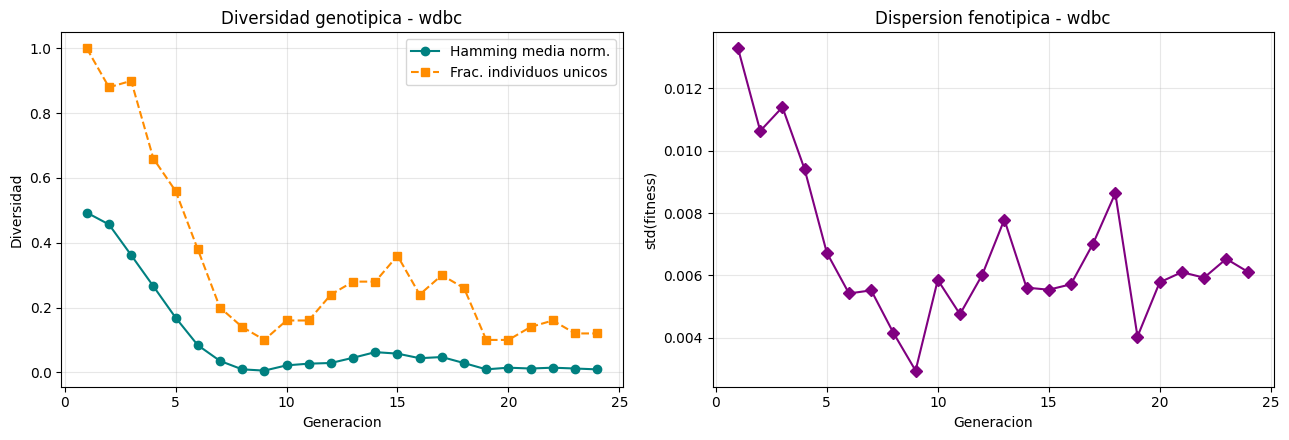

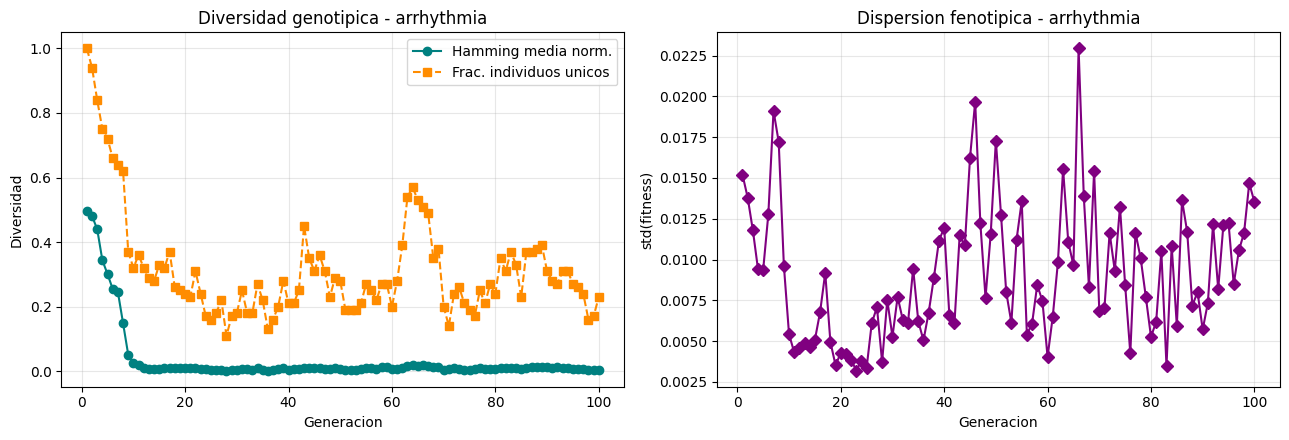

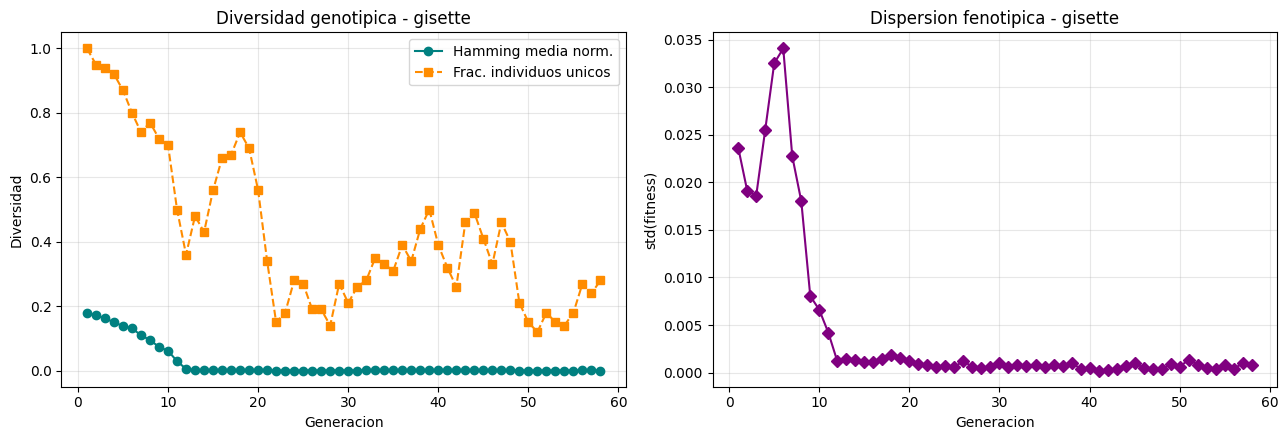

In [16]:
def plot_diversidad(nombre, series):
    g = list(range(1, len(series['mejor_fitness']) + 1))
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].plot(g, series['hamming_media_norm'], 'o-', color='teal', label='Hamming media norm.')
    ax[0].plot(g, series['n_unicos_frac'], 's--', color='darkorange', label='Frac. individuos unicos')
    ax[0].set_xlabel('Generacion'); ax[0].set_ylabel('Diversidad'); ax[0].legend()
    ax[0].set_title(f'Diversidad genotipica - {nombre}'); ax[0].grid(alpha=0.3)
    ax[1].plot(g, series['std_fitness'], 'D-', color='purple')
    ax[1].set_xlabel('Generacion'); ax[1].set_ylabel('std(fitness)')
    ax[1].set_title(f'Dispersion fenotipica - {nombre}'); ax[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'../results/{nombre}_diversidad.png', dpi=150, bbox_inches='tight')
    plt.show()

for nombre in RESULTADOS:
    plot_diversidad(nombre, RESULTADOS[nombre]['series'])

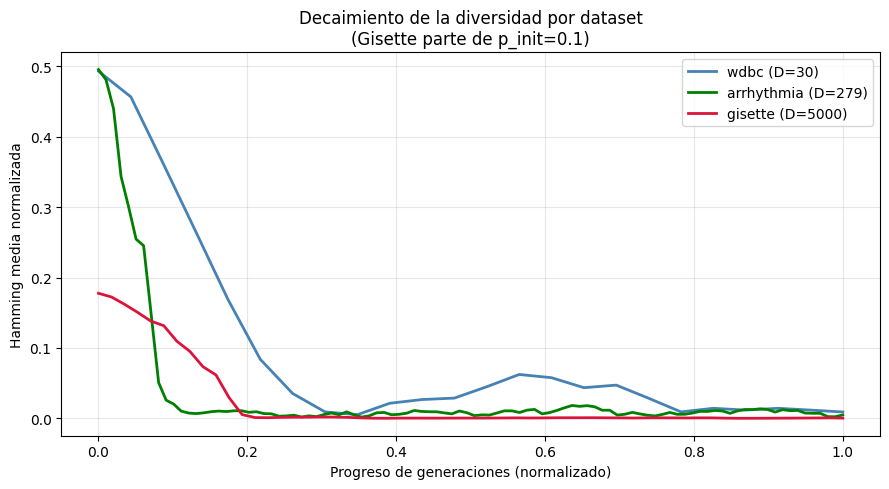

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
for nombre, c in zip(['wdbc', 'arrhythmia', 'gisette'], ['steelblue', 'green', 'crimson']):
    s = RESULTADOS[nombre]['series']['hamming_media_norm']
    ax.plot(np.linspace(0, 1, len(s)), s, '-', color=c, linewidth=2,
            label=f"{nombre} (D={RESULTADOS[nombre]['D']})")
ax.set_xlabel('Progreso de generaciones (normalizado)')
ax.set_ylabel('Hamming media normalizada')
ax.set_title('Decaimiento de la diversidad por dataset\n(Gisette parte de p_init=0.1)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../results/diversidad_comparativa.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Resumen de la validacion del subconjunto final S* con un clasificador distinto
# (LinearSVC) frente al base (GNB), sobre el test held-out. Una fila por dataset.
val_campos = ['dataset', 'D', 'n_caracteristicas_S', 'reduccion_pct',
              'acc_gnb_test', 'acc_linearsvc_test', 'mejora_svc_vs_gnb']
val_filas = []
for nombre in ['wdbc', 'arrhythmia', 'gisette']:
    r = RESULTADOS[nombre]
    gnb, svc = r['acc_gnb_test'], r['acc_svc_test']
    val_filas.append([nombre, r['D'], r['n_sel'], round(r['reduccion'] * 100, 1),
                      f'{gnb:.4f}', f'{svc:.4f}', f'{svc - gnb:+.4f}'])

with open('../results/validacion_linearsvc.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(val_campos); w.writerows(val_filas)

print('VALIDACION DEL SUBCONJUNTO FINAL (LinearSVC vs GNB, test held-out)')
for fila in [val_campos] + val_filas:
    print('  '.join(str(x) for x in fila))
print('\nGuardado en ../results/validacion_linearsvc.csv')

## 3. Estabilidad de seleccion (R = 10 semillas)

Se repite el GA con `R=10` semillas distintas (el *split* held-out se mantiene fijo, solo cambia
la semilla del GA) y se mide la consistencia de las soluciones. Ademas de los indices de
estabilidad del subconjunto (Jaccard medio y Kuncheva) y las frecuencias de seleccion por
caracteristica, se recogen **por semilla** tres metricas de calidad de la solucion:

- **Accuracy** de $S^*$ sobre el *test* held-out con el clasificador base **GNB**
  (consistente con la validacion de la seccion 2; metrica de generalizacion independiente del fitness).
- **Fitness** del mejor individuo ($\alpha\cdot\text{acc}_{CV} - \beta\cdot|S^*|/D$).
- **$|S^*|$**: numero de caracteristicas seleccionadas.

De cada metrica se reporta **media y desviacion tipica** sobre las `R` semillas. Artefactos:

- `results/estabilidad_por_semilla.csv` — una fila por (dataset, semilla): `n_sel`, `fitness`, `acc_gnb_test`.
- `results/estabilidad_resumen.csv` — una fila por dataset: media/std de las tres metricas + Jaccard/Kuncheva/nucleo.
- `results/estabilidad_resumen.png` — grafica resumen (media ± std de accuracy, fitness y |S*|).
- `results/{dataset}_estabilidad.csv` — frecuencias de seleccion por caracteristica (sin cambios).

Coste de reloj dominado por Gisette (~22 min). WDBC y Arrhythmia, segundos.

In [18]:
R = 10
ESTABILIDAD = {}
filas_por_semilla = []   # consolidado global: una fila por (dataset, semilla)

for nombre in ['wdbc', 'arrhythmia', 'gisette']:
    print('=' * 60, f'\nEstabilidad - {nombre} (R={R})')
    X, y, feat, info = cargar_dataset(nombre)
    X = np.ascontiguousarray(X)
    D = X.shape[1]
    params = construir_params(nombre, D)
    X_tr, X_te, y_tr, y_te = split_holdout(X, y)

    subsets = []
    nsel_list, fit_list, acc_list = [], [], []
    t0 = time.time()
    for s in range(R):
        semilla = SEED + s
        evaluador = make_evaluador_spark(X_tr, y_tr, params['cv_folds'],
                                         params['alpha'], params['beta'], NUM_CORES)
        res = run_ga(X_tr, y_tr, params, seed=semilla,
                     evaluador_poblacion=evaluador, collect_diversity=False)
        for bc in evaluador.broadcasts:
            bc.destroy()

        crom = res['mejor_cromosoma']
        subsets.append(crom)

        # --- Metricas por semilla ---
        S = [i for i, g in enumerate(crom) if g == 1]
        n_sel = len(S)
        fit = res['mejor_fitness']
        # Accuracy de S* en test held-out con el clasificador base (GNB),
        # igual que en la validacion de la seccion 2. Metrica de generalizacion
        # independiente del fitness (que se calcula con CV sobre train).
        acc = GaussianNB().fit(X_tr[:, S], y_tr).score(X_te[:, S], y_te)

        nsel_list.append(n_sel); fit_list.append(fit); acc_list.append(acc)
        filas_por_semilla.append([nombre, semilla, n_sel, round(fit, 6), round(acc, 6)])
        print(f'  semilla {semilla}: |S*|={n_sel}, fitness={fit:.6f}, acc_gnb_test={acc:.4f}')
    print(f'  {R} ejecuciones en {time.time()-t0:.1f}s')

    subsets = np.array(subsets)
    jac = jaccard_mean(subsets)
    kun = kuncheva_index(subsets, D)
    frec = selection_frequency(subsets)
    nucleo = int(np.sum(frec >= 0.8))

    # Media y desviacion tipica de las metricas por semilla
    resumen = dict(
        acc_avg=float(np.mean(acc_list)),   acc_std=float(np.std(acc_list)),
        fit_avg=float(np.mean(fit_list)),   fit_std=float(np.std(fit_list)),
        nsel_avg=float(np.mean(nsel_list)), nsel_std=float(np.std(nsel_list)),
    )
    ESTABILIDAD[nombre] = dict(jaccard=jac, kuncheva=kun, frecuencias=frec,
                               nucleo=nucleo, subsets=subsets, feat=feat,
                               acc_list=acc_list, fit_list=fit_list,
                               nsel_list=nsel_list, **resumen)
    print(f'  Jaccard medio={jac:.4f}  Kuncheva={kun:.4f}  nucleo(>=8/10)={nucleo}')
    print(f"  acc={resumen['acc_avg']:.4f}+/-{resumen['acc_std']:.4f}  "
          f"fitness={resumen['fit_avg']:.6f}+/-{resumen['fit_std']:.6f}  "
          f"|S*|={resumen['nsel_avg']:.1f}+/-{resumen['nsel_std']:.1f}")

    # CSV de frecuencias por caracteristica (sin cambios)
    with open(f'../results/{nombre}_estabilidad.csv', 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['caracteristica', 'frecuencia_seleccion'])
        for i, fr in enumerate(frec):
            w.writerow([feat[i] if i < len(feat) else f'V{i}', round(float(fr), 4)])

# --- CSV consolidado: una fila por (dataset, semilla) ---
with open('../results/estabilidad_por_semilla.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['dataset', 'semilla', 'n_sel', 'fitness', 'acc_gnb_test'])
    w.writerows(filas_por_semilla)
print('\nPor-semilla -> ../results/estabilidad_por_semilla.csv')

# --- CSV resumen: media/std por dataset ---
with open('../results/estabilidad_resumen.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['dataset', 'R', 'acc_avg', 'acc_std', 'fitness_avg', 'fitness_std',
                'n_sel_avg', 'n_sel_std', 'jaccard', 'kuncheva', 'nucleo'])
    for nombre in ['wdbc', 'arrhythmia', 'gisette']:
        e = ESTABILIDAD[nombre]
        w.writerow([nombre, R,
                    round(e['acc_avg'], 6), round(e['acc_std'], 6),
                    round(e['fit_avg'], 6), round(e['fit_std'], 6),
                    round(e['nsel_avg'], 2), round(e['nsel_std'], 2),
                    round(e['jaccard'], 4), round(e['kuncheva'], 4), e['nucleo']])
print('Resumen     -> ../results/estabilidad_resumen.csv')

Estabilidad - wdbc (R=10)
  semilla 42: |S*|=6, fitness=0.861943
  semilla 43: |S*|=9, fitness=0.845222
  semilla 44: |S*|=6, fitness=0.861886
  semilla 45: |S*|=4, fitness=0.864110
  semilla 46: |S*|=6, fitness=0.861886
  semilla 47: |S*|=5, fitness=0.858555
  semilla 48: |S*|=4, fitness=0.866331
  semilla 49: |S*|=7, fitness=0.860888
  semilla 50: |S*|=7, fitness=0.851860
  semilla 51: |S*|=3, fitness=0.865165
  10 ejecuciones en 11.4s
  Jaccard medio=0.4265  Kuncheva=0.6524  nucleo(>=8/10)=3
Estabilidad - arrhythmia (R=10)
  semilla 42: |S*|=110, fitness=0.567312
  semilla 43: |S*|=105, fitness=0.540694
  semilla 44: |S*|=109, fitness=0.245811
  semilla 45: |S*|=100, fitness=0.419549
  semilla 46: |S*|=103, fitness=0.233514
  semilla 47: |S*|=114, fitness=0.420299
  semilla 48: |S*|=105, fitness=0.280802
  semilla 49: |S*|=121, fitness=0.454879
  semilla 50: |S*|=82, fitness=0.275407
  semilla 51: |S*|=105, fitness=0.249994
  10 ejecuciones en 75.5s
  Jaccard medio=0.2975  Kuncheva=

/Users/franmateos/Documents/Formacion/Master MDS/TFM/Desarrollo/AFSGAW/spark_env/lib/python3.9/site-packages/sklearn/datasets/_openml.py:971: UserWarning: Version 1 of dataset gisette is inactive, meaning that issues have been found in the dataset. Try using a newer version from this URL: https://openml.org/data/v1/download/1594037/gisette.sparse_arff
  warn(
26/06/18 11:20:37 WARN TaskSetManager: Stage 1422 contains a task of very large size (1121 KiB). The maximum recommended task size is 1000 KiB.
26/06/18 11:20:40 WARN TaskSetManager: Stage 1423 contains a task of very large size (1053 KiB). The maximum recommended task size is 1000 KiB.
26/06/18 11:20:49 WARN TaskSetManager: Stage 1424 contains a task of very large size (1261 KiB). The maximum recommended task size is 1000 KiB.
26/06/18 11:20:51 WARN TaskSetManager: Stage 1425 contains a task of very large size (1115 KiB). The maximum recommended task size is 1000 KiB.


  semilla 42: |S*|=483, fitness=0.822013


26/06/18 11:23:10 WARN TaskSetManager: Stage 1480 contains a task of very large size (1121 KiB). The maximum recommended task size is 1000 KiB.
26/06/18 11:23:14 WARN TaskSetManager: Stage 1481 contains a task of very large size (1053 KiB). The maximum recommended task size is 1000 KiB.
26/06/18 11:23:19 WARN TaskSetManager: Stage 1482 contains a task of very large size (1222 KiB). The maximum recommended task size is 1000 KiB.
26/06/18 11:23:21 WARN TaskSetManager: Stage 1483 contains a task of very large size (1084 KiB). The maximum recommended task size is 1000 KiB.


  semilla 43: |S*|=531, fitness=0.816829


...

  semilla 49: |S*|=571, fitness=0.822641


26/06/18 11:57:47 WARN TaskSetManager: Stage 2111 contains a task of very large size (1121 KiB). The maximum recommended task size is 1000 KiB.
26/06/18 11:57:52 WARN TaskSetManager: Stage 2112 contains a task of very large size (1047 KiB). The maximum recommended task size is 1000 KiB.
26/06/18 11:57:56 WARN TaskSetManager: Stage 2113 contains a task of very large size (1114 KiB). The maximum recommended task size is 1000 KiB.


  semilla 50: |S*|=518, fitness=0.822232


26/06/18 12:02:06 WARN TaskSetManager: Stage 2180 contains a task of very large size (1121 KiB). The maximum recommended task size is 1000 KiB.
26/06/18 12:02:11 WARN TaskSetManager: Stage 2181 contains a task of very large size (1121 KiB). The maximum recommended task size is 1000 KiB.
26/06/18 12:02:15 WARN TaskSetManager: Stage 2182 contains a task of very large size (1077 KiB). The maximum recommended task size is 1000 KiB.


  semilla 51: |S*|=497, fitness=0.820080
  10 ejecuciones en 2660.6s
  Jaccard medio=0.0610  Kuncheva=0.0108  nucleo(>=8/10)=0


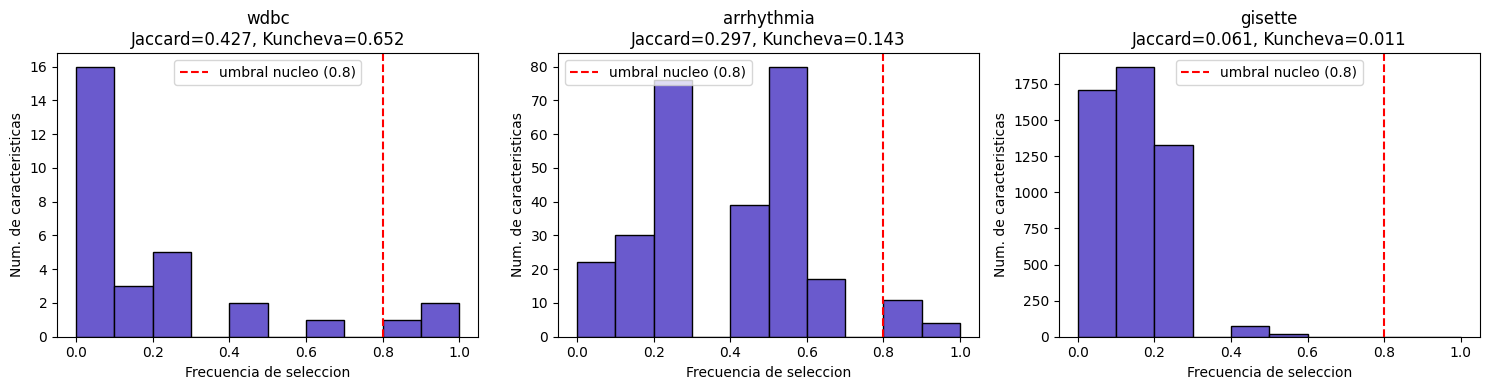

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nombre in zip(axes, ['wdbc', 'arrhythmia', 'gisette']):
    frec = ESTABILIDAD[nombre]['frecuencias']
    ax.hist(frec, bins=np.linspace(0, 1, 11), color='slateblue', edgecolor='black')
    ax.axvline(0.8, color='red', linestyle='--', label='umbral nucleo (0.8)')
    ax.set_xlabel('Frecuencia de seleccion'); ax.set_ylabel('Num. de caracteristicas')
    ax.set_title(f"{nombre}\nJaccard={ESTABILIDAD[nombre]['jaccard']:.3f}, "
                 f"Kuncheva={ESTABILIDAD[nombre]['kuncheva']:.3f}")
    ax.legend()
plt.tight_layout()
plt.savefig('../results/estabilidad_frecuencias.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Grafica resumen de estabilidad: media +/- desviacion tipica sobre las R semillas.
# Un panel por metrica (accuracy, fitness, |S*|); barras por dataset con barra de error.
nombres = ['wdbc', 'arrhythmia', 'gisette']
x = np.arange(len(nombres))
paneles = [
    ('Accuracy de S* (GNB, test held-out)', 'acc_avg', 'acc_std', 'seagreen',  False),
    ('Fitness del mejor individuo',          'fit_avg', 'fit_std', 'steelblue', False),
    ('|S*| (num. caracteristicas)',          'nsel_avg', 'nsel_std', 'indianred', True),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (titulo, kavg, kstd, color, es_nsel) in zip(axes, paneles):
    medias = [ESTABILIDAD[n][kavg] for n in nombres]
    stds   = [ESTABILIDAD[n][kstd] for n in nombres]
    ax.bar(x, medias, yerr=stds, capsize=6, color=color, edgecolor='black', alpha=0.85)
    ax.set_xticks(x); ax.set_xticklabels(nombres)
    ax.set_title(titulo)
    ax.grid(True, axis='y', alpha=0.3)
    if es_nsel:
        ax.set_yscale('log')   # |S*| varia de ~8 (wdbc) a ~miles (gisette)
    fmt = (lambda m, sd: f'{m:.1f}\n±{sd:.1f}') if es_nsel else (lambda m, sd: f'{m:.3f}\n±{sd:.3f}')
    for xi, m, sd in zip(x, medias, stds):
        ax.annotate(fmt(m, sd), (xi, m), textcoords='offset points', xytext=(0, 6),
                    ha='center', va='bottom', fontsize=9)
fig.suptitle(f'Estabilidad de la seleccion sobre R={R} semillas (media ± desviacion tipica)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/estabilidad_resumen.png', dpi=150, bbox_inches='tight')
plt.show()
print('Grafica -> ../results/estabilidad_resumen.png')

## 4. Escalabilidad paralela: speed-up por dataset

Honesto que WDBC no acelere (overhead de Spark > beneficio) y que Gisette si.

In [ ]:
def medir_speedup(X_tr, y_tr, params, poblacion, slices_list, repeticiones=3):
    """T_serie y T_spark(n) evaluando una poblacion fija. Devuelve lista de filas."""
    cv, a, b = params['cv_folds'], params['alpha'], params['beta']
    # Compactar a int8 (misma poblacion para serie y Spark); evita el aviso
    # "task of very large size" al paralelizar cromosomas largos como Gisette.
    poblacion = list(np.asarray(poblacion, dtype=np.int8))
    # Baseline en serie (sin Spark)
    ts = []
    for _ in range(repeticiones):
        t0 = time.time()
        [evaluar_fitness(c, X_tr, y_tr, cv, a, b) for c in poblacion]
        ts.append(time.time() - t0)
    t_serie = float(np.median(ts))

    X_bc, y_bc = sc.broadcast(X_tr), sc.broadcast(y_tr)
    filas = [dict(modo='serie', n=1, t=t_serie, speedup=1.0, eficiencia=1.0)]
    for n in slices_list:
        tn = []
        for _ in range(repeticiones):
            t0 = time.time()
            sc.parallelize(poblacion, numSlices=n).map(
                lambda c: evaluar_fitness(c, X_bc.value, y_bc.value, cv, a, b)
            ).collect()
            tn.append(time.time() - t0)
        tmed = float(np.median(tn))
        filas.append(dict(modo='spark', n=n, t=tmed,
                          speedup=t_serie / tmed, eficiencia=(t_serie / tmed) / n))
    X_bc.destroy(); y_bc.destroy()
    return filas

SPEEDUP = {}
for nombre in ['wdbc', 'arrhythmia', 'gisette']:
    X, y, feat, info = cargar_dataset(nombre)
    X = np.ascontiguousarray(X)
    D = X.shape[1]
    params = construir_params(nombre, D)
    X_tr, X_te, y_tr, y_te = split_holdout(X, y)
    np.random.seed(SEED)
    poblacion = [list(np.random.binomial(1, params['p_init'], D))
                 for _ in range(params['P'])]
    filas = medir_speedup(X_tr, y_tr, params, poblacion, slices_list=[1, 2, 4, 8])
    SPEEDUP[nombre] = filas
    print(f'{nombre}: ' + '  '.join(
        f"{f['modo']}{f['n']}={f['t']:.2f}s(S={f['speedup']:.2f})" for f in filas))
    with open(f'../results/{nombre}_speedup.csv', 'w', newline='') as fcsv:
        w = csv.DictWriter(fcsv, fieldnames=['modo', 'n', 't', 'speedup', 'eficiencia'])
        w.writeheader()
        for f in filas:
            w.writerow({k: (round(v, 4) if isinstance(v, float) else v)
                        for k, v in f.items()})

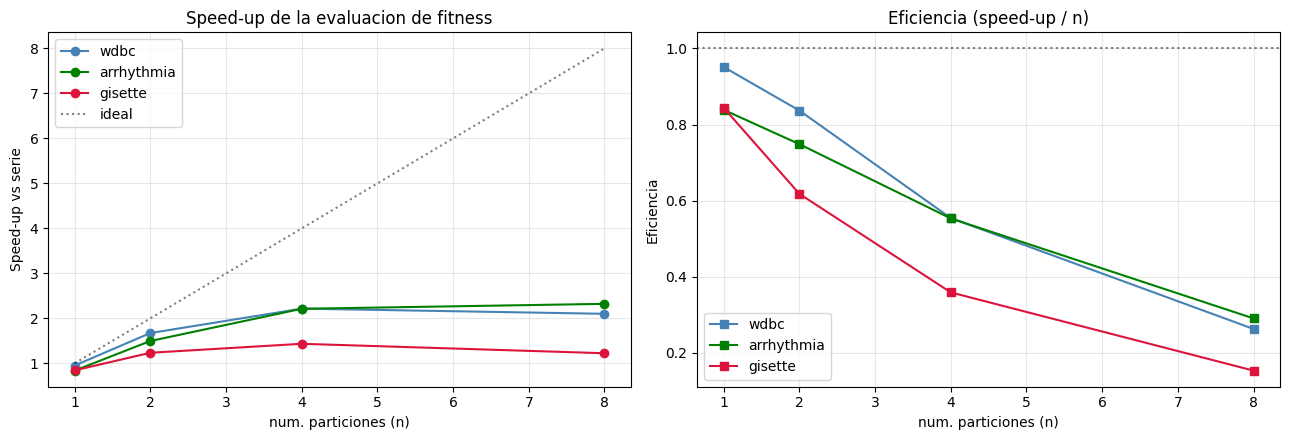

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, c in zip(['wdbc', 'arrhythmia', 'gisette'], ['steelblue', 'green', 'crimson']):
    spark_rows = [f for f in SPEEDUP[nombre] if f['modo'] == 'spark']
    ns = [f['n'] for f in spark_rows]
    ax[0].plot(ns, [f['speedup'] for f in spark_rows], 'o-', color=c, label=nombre)
    ax[1].plot(ns, [f['eficiencia'] for f in spark_rows], 's-', color=c, label=nombre)
ax[0].plot([1, 8], [1, 8], 'k:', alpha=0.5, label='ideal')
ax[0].set_xlabel('num. particiones (n)'); ax[0].set_ylabel('Speed-up vs serie'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].axhline(1.0, color='k', linestyle=':', alpha=0.5)
ax[1].set_xlabel('num. particiones (n)'); ax[1].set_ylabel('Eficiencia'); ax[1].legend(); ax[1].grid(alpha=0.3)
ax[0].set_title('Speed-up de la evaluacion de fitness')
ax[1].set_title('Eficiencia (speed-up / n)')
plt.tight_layout()
plt.savefig('../results/speedup_comparativo.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Consolidacion: tabla de escalabilidad algoritmica

Tabla unica por dataset que cruza tamano/dimensionalidad, calidad de la solucion, estabilidad y
tiempos. Incluye tanto los valores de la **ejecucion de referencia** (seed 42, seccion 2) como los
**agregados sobre R=10 semillas** (seccion 3), con sufijo `_R` y en formato media/desviacion tipica:

- `acc_gnb_test`, `acc_svc_test`: accuracy de $S^*$ en test held-out (ejecucion de referencia).
- `acc_avg_R` / `acc_std_R`: accuracy GNB held-out, media ± std sobre las R semillas.
- `fitness_avg_R` / `fitness_std_R`: fitness del mejor individuo, media ± std.
- `n_sel_avg_R` / `n_sel_std_R`: $|S^*|$, media ± std.
- `jaccard`, `kuncheva`: indices de estabilidad del subconjunto.

In [22]:
campos = ['dataset', 'D', 'gen', 'n_sel', 'reduccion_pct',
          'acc_gnb_test', 'acc_svc_test',
          'acc_avg_R', 'acc_std_R',
          'fitness_avg_R', 'fitness_std_R',
          'n_sel_avg_R', 'n_sel_std_R',
          'jaccard', 'kuncheva',
          't_total_s', 't_gen_s']

def _r(d, k, nd=4):
    v = d.get(k, float('nan'))
    return round(v, nd)

filas = []
for nombre in ['wdbc', 'arrhythmia', 'gisette']:
    r = RESULTADOS[nombre]
    e = ESTABILIDAD.get(nombre, {})
    filas.append([
        nombre, r['D'], r['gen'], r['n_sel'], round(r['reduccion'] * 100, 1),
        round(r['acc_gnb_test'], 4), round(r['acc_svc_test'], 4),
        _r(e, 'acc_avg'), _r(e, 'acc_std'),
        _r(e, 'fit_avg', 6), _r(e, 'fit_std', 6),
        _r(e, 'nsel_avg', 2), _r(e, 'nsel_std', 2),
        _r(e, 'jaccard'), _r(e, 'kuncheva'),
        r['t_total'], r['t_gen'],
    ])

with open('../results/escalabilidad_algoritmica.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(campos); w.writerows(filas)

print('TABLA DE ESCALABILIDAD ALGORITMICA')
print('  '.join(campos))
for fila in filas:
    print('  '.join(str(x) for x in fila))
print('\nGuardada en ../results/escalabilidad_algoritmica.csv')

TABLA DE ESCALABILIDAD ALGORITMICA
dataset  D  gen  n_sel  reduccion_pct  acc_gnb_test  acc_svc_test  jaccard  kuncheva  t_total_s  t_gen_s
wdbc  30  24  6  80.0  0.9474  0.9649  0.4265  0.6524  1.954  0.081
arrhythmia  279  100  110  60.6  0.5662  0.625  0.2975  0.1434  9.596  0.096
gisette  5000  58  483  90.3  0.921  0.939  0.061  0.0108  121.241  2.09

Guardada en ../results/escalabilidad_algoritmica.csv


In [23]:
parar_spark(spark)
print('Spark detenido. Experimento completo.')

✓ Spark session detenida
Spark detenido. Experimento completo.
